# Diabetes Health Indicators – Machine Learning - Project Group 3

## 1. Dataset Loading and Inspection


In [1]:
import pandas as pd

df = pd.read_csv("diabetes_binary_health_indicators_BRFSS2015.csv")

df.head()

,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 253680 entries, 0 to 253679
Data columns (total 22 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   Diabetes_binary       253680 non-null  float64
 1   HighBP                253680 non-null  float64
 2   HighChol              253680 non-null  float64
 3   CholCheck             253680 non-null  float64
 4   BMI                   253680 non-null  float64
 5   Smoker                253680 non-null  float64
 6   Stroke                253680 non-null  float64
 7   HeartDiseaseorAttack  253680 non-null  float64
 8   PhysActivity          253680 non-null  float64
 9   Fruits                253680 non-null  float64
 10  Veggies               253680 non-null  float64
 11  HvyAlcoholConsump     253680 non-null  float64
 12  AnyHealthcare         253680 non-null  float64
 13  NoDocbcCost           253680 non-null  float64
 14  GenHlth               253680 non-null  float64
 15  MentHlth   

## 2. Exploratory Data Analysis (EDA)

This section examines the distribution of diabetes classes
and explores relationships between diabetes status (target variable) and
health indicators (features) such as BMI, blood pressure, physical
activity, and age.

In [3]:
df["Diabetes_binary"].value_counts()

Diabetes_binary
0.0    218334
1.0     35346
Name: count, dtype: int64

In [4]:
df["Diabetes_binary"].value_counts(normalize=True) * 100

Diabetes_binary
0.0    86.066698
1.0    13.933302
Name: proportion, dtype: float64

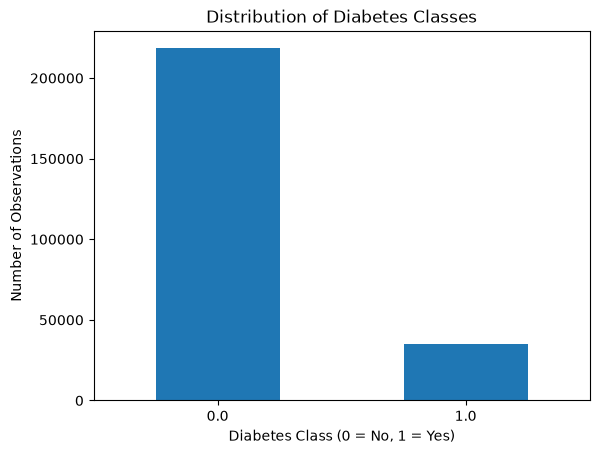

In [5]:
import matplotlib.pyplot as plt

class_counts = df["Diabetes_binary"].value_counts().sort_index()

class_counts.plot(kind="bar")

plt.title("Distribution of Diabetes Classes")
plt.xlabel("Diabetes Class (0 = No, 1 = Yes)")
plt.ylabel("Number of Observations")
plt.xticks(rotation=0)
plt.show()

In [6]:
df.groupby("Diabetes_binary")["BMI"].mean()

Diabetes_binary
0.0    27.805770
1.0    31.944011
Name: BMI, dtype: float64

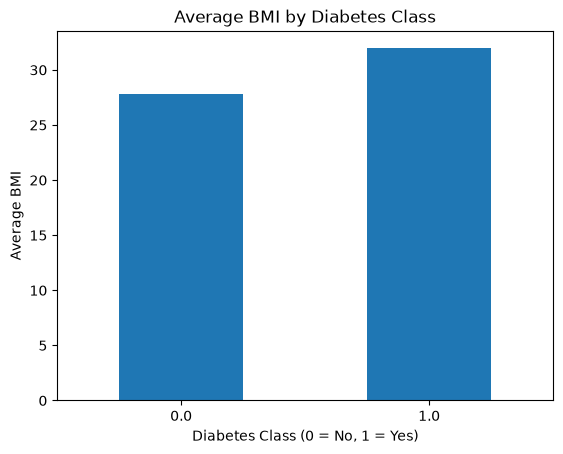

In [7]:
average_bmi = df.groupby("Diabetes_binary")["BMI"].mean()

average_bmi.plot(kind="bar")

plt.title("Average BMI by Diabetes Class")
plt.xlabel("Diabetes Class (0 = No, 1 = Yes)")
plt.ylabel("Average BMI")
plt.xticks(rotation=0)
plt.show()

In [8]:
df.groupby("Diabetes_binary")["HighBP"].mean() * 100

Diabetes_binary
0.0    37.660190
1.0    75.267357
Name: HighBP, dtype: float64

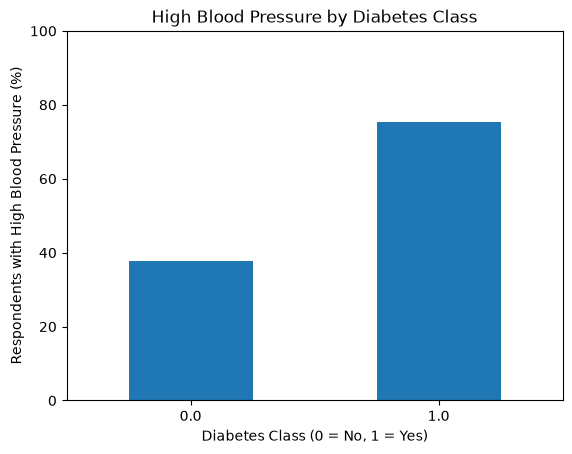

In [9]:
high_bp_percent = df.groupby("Diabetes_binary")["HighBP"].mean() * 100

high_bp_percent.plot(kind="bar")

plt.title("High Blood Pressure by Diabetes Class")
plt.xlabel("Diabetes Class (0 = No, 1 = Yes)")
plt.ylabel("Respondents with High Blood Pressure (%)")
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.show()

In [10]:
df.groupby("Diabetes_binary")["PhysActivity"].mean() * 100

Diabetes_binary
0.0    77.694267
1.0    63.053811
Name: PhysActivity, dtype: float64

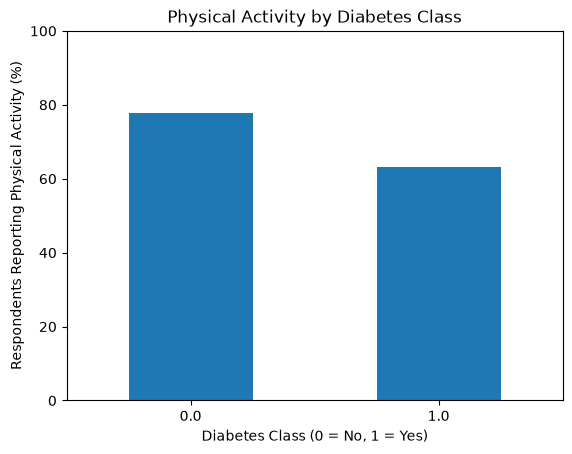

In [11]:
activity_percent = df.groupby("Diabetes_binary")["PhysActivity"].mean() * 100

activity_percent.plot(kind="bar")

plt.title("Physical Activity by Diabetes Class")
plt.xlabel("Diabetes Class (0 = No, 1 = Yes)")
plt.ylabel("Respondents Reporting Physical Activity (%)")
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.show()

In [12]:
df.groupby("Age")["Diabetes_binary"].mean() * 100

Age
1.0      1.368421
2.0      1.842590
3.0      2.822979
4.0      4.528684
5.0      6.504920
6.0      8.789545
7.0     11.735198
8.0     13.826544
9.0     17.245217
10.0    20.370255
11.0    21.845918
12.0    21.295369
13.0    18.481829
Name: Diabetes_binary, dtype: float64

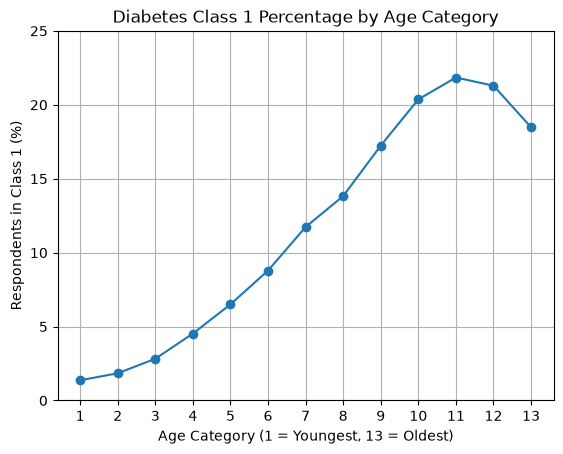

In [13]:
age_diabetes_percent = (
    df.groupby("Age")["Diabetes_binary"].mean() * 100
)

age_diabetes_percent.plot(
    kind="line",
    marker="o"
)

plt.title("Diabetes Class 1 Percentage by Age Category")
plt.xlabel("Age Category (1 = Youngest, 13 = Oldest)")
plt.ylabel("Respondents in Class 1 (%)")
plt.xticks(range(1, 14))
plt.ylim(0, 25)
plt.grid(True)
plt.show()

## 3. Data Quality Checks

This section examines missing values, duplicate observations,
and feature value ranges to assess the quality of the dataset.

No missing values were detected. We identified 24,206
repeated rows, which were retained because identical survey
responses do not necessarily represent duplicate respondents.

In [14]:
df.isnull().sum()

Diabetes_binary         0
HighBP                  0
HighChol                0
CholCheck               0
BMI                     0
Smoker                  0
Stroke                  0
HeartDiseaseorAttack    0
PhysActivity            0
Fruits                  0
Veggies                 0
HvyAlcoholConsump       0
AnyHealthcare           0
NoDocbcCost             0
GenHlth                 0
MentHlth                0
PhysHlth                0
DiffWalk                0
Sex                     0
Age                     0
Education               0
Income                  0
dtype: int64

In [15]:
df.duplicated().sum()

np.int64(24206)

In [16]:
df.groupby("Diabetes_binary").apply(
    lambda group: group.duplicated().sum(),
    include_groups=False
)

Diabetes_binary
0.0    23957
1.0      249
dtype: int64

In [17]:
df[["Diabetes_binary", "HighBP", "BMI", "Age",
    "GenHlth", "PhysHlth", "Education", "Income"]].agg(
    ["min", "max"]
)


,Diabetes_binary,HighBP,BMI,Age,GenHlth,PhysHlth,Education,Income
min,0.0,0.0,12.0,1.0,1.0,0.0,1.0,1.0
max,1.0,1.0,98.0,13.0,5.0,30.0,6.0,8.0


In [18]:
df.agg(["min", "max"]).T

,min,max
Diabetes_binary,0.0,1.0
HighBP,0.0,1.0
HighChol,0.0,1.0
CholCheck,0.0,1.0
BMI,12.0,98.0
Smoker,0.0,1.0
Stroke,0.0,1.0
HeartDiseaseorAttack,0.0,1.0
PhysActivity,0.0,1.0
Fruits,0.0,1.0


## 4. Data Preprocessing

The dataset was divided into 21 input features (X) and
one target variable (y), Diabetes_binary.

The observations were split into 80% training data and
20% test data using stratified sampling to preserve
the original class distribution.

For Logistic Regression, numerical features were
standardized, ordinal features were one-hot encoded,
and binary features retained their original values.

Preprocessing was fitted only on the training data
to prevent data leakage.

In [19]:
X = df.drop(columns=["Diabetes_binary"])
y = df["Diabetes_binary"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (253680, 21)
y shape: (253680,)


In [20]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training observations:", X_train.shape[0])
print("Test observations:", X_test.shape[0])

Training observations: 202944
Test observations: 50736


In [21]:
numerical_features = ["BMI", "MentHlth", "PhysHlth"]

ordinal_features = ["Age", "Education", "Income", "GenHlth"]

binary_features = [
    col for col in X_train.columns
    if col not in numerical_features + ordinal_features
]

print("Numerical:", numerical_features)
print("Ordinal:", ordinal_features)
print("Binary:", binary_features)

print("Total features:",
      len(numerical_features) +
      len(ordinal_features) +
      len(binary_features))

Numerical: ['BMI', 'MentHlth', 'PhysHlth']
Ordinal: ['Age', 'Education', 'Income', 'GenHlth']
Binary: ['HighBP', 'HighChol', 'CholCheck', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'DiffWalk', 'Sex']
Total features: 21


In [22]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

preprocessor = ColumnTransformer(
    transformers=[
        ("numerical", StandardScaler(), numerical_features),
        ("ordinal", OneHotEncoder(handle_unknown="ignore"),
         ordinal_features),
        ("binary", "passthrough", binary_features)
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


## 5. Logistic Regression

Logistic Regression was selected as the first classification
model because it provides a relatively simple and
interpretable baseline.

The model was trained using 202,944 observations,
with preprocessing applied through a Scikit-Learn pipeline.

The model was evaluated using accuracy, precision,
recall, F1-score, a confusion matrix, and ROC-AUC.

The Logistic Regression model achieved:
- Accuracy: 86.34%
- Class 1 Precision: 53.38%
- Class 1 Recall: 15.32%
- Class 1 F1-score: 0.2381
- ROC-AUC: 0.8209

Although the overall accuracy was relatively high,
the model identified only 15.32% of actual Class 1
observations at the default classification threshold.

In [23]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

logistic_model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

print("Logistic Regression pipeline created successfully!")

Logistic Regression pipeline created successfully!


In [24]:
logistic_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [25]:
y_pred_logistic = logistic_model.predict(X_test)

print("First 20 predictions:")
print(y_pred_logistic[:20])

print("Total predictions:", len(y_pred_logistic))

First 20 predictions:
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
Total predictions: 50736


In [26]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_logistic))


              precision    recall  f1-score   support

         0.0       0.88      0.98      0.92     43667
         1.0       0.53      0.15      0.24      7069

    accuracy                           0.86     50736
   macro avg       0.71      0.57      0.58     50736
weighted avg       0.83      0.86      0.83     50736



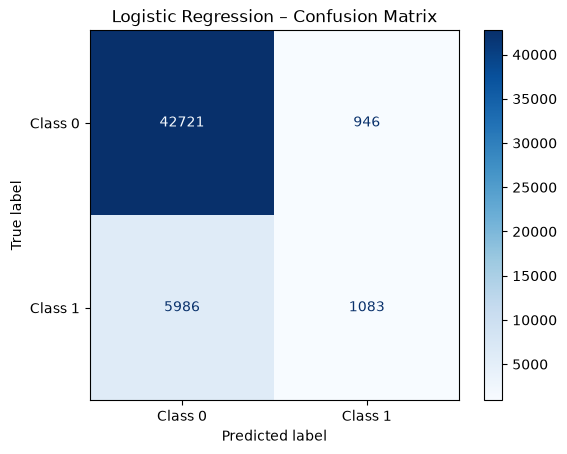

In [27]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred_logistic)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Class 0", "Class 1"]
)

disp.plot(cmap="Blues")
plt.title("Logistic Regression – Confusion Matrix")
plt.show()

In [28]:
from sklearn.metrics import roc_auc_score

y_prob_logistic = logistic_model.predict_proba(X_test)[:, 1]

auc_logistic = roc_auc_score(y_test, y_prob_logistic)

print("Logistic Regression ROC-AUC:", round(auc_logistic, 4))

Logistic Regression ROC-AUC: 0.8209


## 6. Random Forest

Random Forest was selected as the second classification
model to compare with Logistic Regression.

Random Forest combines multiple decision trees and can
capture nonlinear relationships between health indicators.

The model was trained using 202,944 observations and
100 decision trees.

Unlike Logistic Regression, Random Forest was trained
using the original feature values without standardization.

The Random Forest model achieved:
- Accuracy: 85.94%
- Class 1 Precision: 48.76%
- Class 1 Recall: 17.84%
- Class 1 F1-score: 0.2612
- ROC-AUC: 0.7944

Random Forest achieved slightly higher recall and F1-score
for Class 1 than Logistic Regression, but lower precision
and ROC-AUC.

In [29]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

print("Random Forest model created successfully!")

Random Forest model created successfully!


In [30]:
rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [31]:
y_pred_rf = rf_model.predict(X_test)

print(classification_report(y_test, y_pred_rf))

              precision    recall  f1-score   support

         0.0       0.88      0.97      0.92     43667
         1.0       0.49      0.18      0.26      7069

    accuracy                           0.86     50736
   macro avg       0.68      0.57      0.59     50736
weighted avg       0.82      0.86      0.83     50736



In [32]:
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

auc_rf = roc_auc_score(y_test, y_prob_rf)

print("Random Forest ROC-AUC:", round(auc_rf, 4))
print("Logistic Regression ROC-AUC:", round(auc_logistic, 4))

Random Forest ROC-AUC: 0.7944
Logistic Regression ROC-AUC: 0.8209


In [33]:
from sklearn.metrics import average_precision_score

ap_logistic = average_precision_score(y_test, y_prob_logistic)
ap_rf = average_precision_score(y_test, y_prob_rf)

print("Logistic Regression Average Precision:", round(ap_logistic, 4))
print("Random Forest Average Precision:", round(ap_rf, 4))

Logistic Regression Average Precision: 0.4022
Random Forest Average Precision: 0.3678


## 7. Feature Importance

This section investigates which health indicators
contributed most to the Random Forest model's predictions.

The five highest-ranked features were:

1. BMI (18.41%)
2. Age (12.24%)
3. Income (9.87%)
4. Physical Health (8.46%)
5. Education (7.03%)

Feature importance was calculated using Random Forest's
impurity-based importance scores.

These scores describe how the model uses the different
features, but they do not establish causation.

In [34]:
import pandas as pd

feature_importance = pd.Series(
    rf_model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

print(feature_importance.head(10))

BMI          0.184123
Age          0.122429
Income       0.098747
PhysHlth     0.084610
Education    0.070320
GenHlth      0.070139
MentHlth     0.064511
HighBP       0.042603
Fruits       0.033205
Smoker       0.033193
dtype: float64


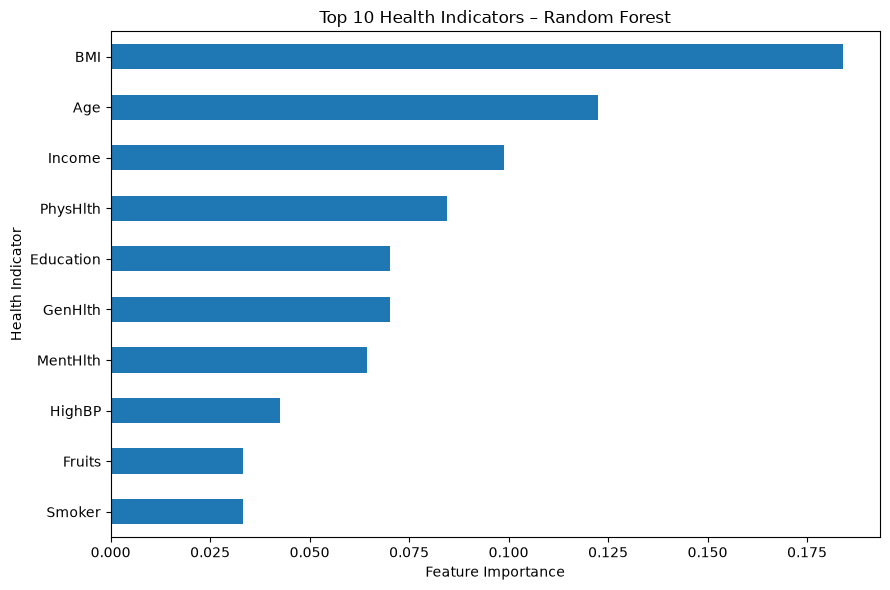

In [35]:
feature_importance.head(10).sort_values().plot(
    kind="barh",
    figsize=(9, 6)
)

plt.title("Top 10 Health Indicators – Random Forest")
plt.xlabel("Feature Importance")
plt.ylabel("Health Indicator")
plt.tight_layout()
plt.show()

## 8. Model Evaluation and Conclusions

This section compares Logistic Regression and Random Forest
using accuracy, precision, recall, F1-score, ROC-AUC,
and Average Precision.

Logistic Regression achieved better overall ranking
performance, with a ROC-AUC of 0.8209 compared with
0.7944 for Random Forest.

Random Forest achieved slightly higher Class 1 recall
(17.84% versus 15.32%) and F1-score
(0.2612 versus 0.2381).

Both models struggled to identify most Class 1
observations at the default classification threshold.

These findings demonstrate why multiple evaluation
metrics are necessary for imbalanced classification.

In [36]:
from sklearn.metrics import accuracy_score, precision_score
from sklearn.metrics import recall_score, f1_score

results = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [
        accuracy_score(y_test, y_pred_logistic),
        accuracy_score(y_test, y_pred_rf)
    ],
    "Precision (Class 1)": [
        precision_score(y_test, y_pred_logistic),
        precision_score(y_test, y_pred_rf)
    ],
    "Recall (Class 1)": [
        recall_score(y_test, y_pred_logistic),
        recall_score(y_test, y_pred_rf)
    ],
    "F1-score (Class 1)": [
        f1_score(y_test, y_pred_logistic),
        f1_score(y_test, y_pred_rf)
    ],
    "ROC-AUC": [auc_logistic, auc_rf],
    "Average Precision": [ap_logistic, ap_rf]
})

results.round(4)

,Model,Accuracy,Precision (Class 1),Recall (Class 1),F1-score (Class 1),ROC-AUC,Average Precision
0,Logistic Regression,0.8634,0.5338,0.1532,0.2381,0.8209,0.4022
1,Random Forest,0.8594,0.4876,0.1784,0.2612,0.7944,0.3678
